Import library

In [2]:
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
df=pd.read_csv('seoul_air_quality_2022_english.csv')
df_raw=df.copy()
df.head(10)

,datetime,station_code,district,CO,NO2,O3,PM10,PM2.5,SO2,population,area_km2,population_density,households,male_population,female_population,district_code,year
0,1/1/2022 0:00,101,Jongno-gu,0.4,0.016,0.026,23.0,12.0,0.003,152211,23.91,6365,72524,72980,79231,1111000000,2022
1,1/1/2022 0:00,102,Jung-gu,0.4,0.024,0.016,25.0,10.0,0.003,130785,9.96,13131,63139,63377,67408,1114000000,2022
2,1/1/2022 0:00,103,Yongsan-gu,0.4,0.020,0.020,24.0,13.0,0.003,233284,21.87,10668,109805,113012,120272,1117000000,2022
3,1/1/2022 0:00,104,Eunpyeong-gu,0.8,0.019,0.019,19.0,10.0,0.004,470602,29.71,15838,213876,224163,246439,1138000000,2022
4,1/1/2022 0:00,105,Seodaemun-gu,0.7,0.020,0.019,23.0,13.0,NaN,319554,17.63,18129,145797,150094,169460,1141000000,2022
5,1/1/2022 0:00,106,Mapo-gu,0.4,0.026,0.014,18.0,6.0,0.002,375585,23.85,15745,180084,175006,200579,1144000000,2022
6,1/1/2022 0:00,107,Seongdong-gu,0.3,0.017,0.024,19.0,5.0,0.003,288234,16.82,17136,133305,139691,148543,1120000000,2022
7,1/1/2022 0:00,108,Gwangjin-gu,0.7,0.025,0.018,17.0,8.0,0.001,351252,17.06,20586,169291,168197,183055,1121500000,2022
8,1/1/2022 0:00,109,Dongdaemun-gu,0.4,0.021,0.022,16.0,11.0,0.002,353601,14.22,24873,169873,171903,181698,1123000000,2022
9,1/1/2022 0:00,110,Jungnang-gu,0.4,0.019,0.025,21.0,8.0,0.003,390140,18.50,21092,187413,191422,198718,1126000000,2022


Exploretary data analysis

In [4]:
print(df.shape)
df.info()
display(df.describe())
df.isnull().sum()
print((df.isnull().sum())*100/len(df))
#Check duplicated date
display(df.duplicated(subset=['district','datetime']).sum())


(216545, 17)
<class 'pandas.DataFrame'>
RangeIndex: 216545 entries, 0 to 216544
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   datetime            216545 non-null  str    
 1   station_code        216545 non-null  int64  
 2   district            216545 non-null  str    
 3   CO                  215142 non-null  float64
 4   NO2                 215540 non-null  float64
 5   O3                  215209 non-null  float64
 6   PM10                214136 non-null  float64
 7   PM2.5               214805 non-null  float64
 8   SO2                 214839 non-null  float64
 9   population          216545 non-null  int64  
 10  area_km2            216545 non-null  float64
 11  population_density  216545 non-null  int64  
 12  households          216545 non-null  int64  
 13  male_population     216545 non-null  int64  
 14  female_population   216545 non-null  int64  
 15  district_code       216545 non-n

,station_code,CO,NO2,O3,PM10,PM2.5,SO2,population,area_km2,population_density,households,male_population,female_population,district_code,year
count,216545.000000,215142.000000,215540.000000,215209.000000,214136.000000,214805.000000,214839.000000,216545.000000,216545.000000,216545.000000,216545.000000,216545.000000,216545.000000,2.165450e+05,216545.0
mean,113.006812,0.437070,0.020868,0.029275,32.861625,18.378618,0.002886,386814.131368,24.237395,16790.225316,177867.498377,187068.209924,199745.921444,1.141691e+09,2022.0
std,7.214851,0.185666,0.013388,0.019398,22.842114,13.907109,0.000843,122930.793712,9.121672,4603.200653,55573.744517,59252.031769,63846.926920,1.863222e+07,0.0
min,101.000000,0.100000,0.001000,0.000000,1.000000,1.000000,0.001000,130785.000000,9.960000,6365.000000,63139.000000,63377.000000,67408.000000,1.111000e+09,2022.0
25%,107.000000,0.300000,0.011000,0.015000,19.000000,9.000000,0.002000,313989.000000,17.410000,13862.000000,144313.000000,150094.000000,161814.000000,1.126000e+09,2022.0
50%,113.000000,0.400000,0.017000,0.027000,28.000000,15.000000,0.003000,390432.000000,23.600000,16951.000000,181187.000000,191422.000000,201821.000000,1.141000e+09,2022.0
75%,119.000000,0.500000,0.028000,0.040000,41.000000,24.000000,0.003000,464037.000000,29.570000,19616.000000,202169.000000,224163.000000,237062.000000,1.156000e+09,2022.0
max,125.000000,2.000000,0.096000,0.167000,482.000000,126.000000,0.016000,664514.000000,46.970000,25509.000000,284853.000000,319743.000000,344771.000000,1.174000e+09,2022.0


datetime              0.000000
station_code          0.000000
district              0.000000
CO                    0.647902
NO2                   0.464107
O3                    0.616962
PM10                  1.112471
PM2.5                 0.803528
SO2                   0.787827
population            0.000000
area_km2              0.000000
population_density    0.000000
households            0.000000
male_population       0.000000
female_population     0.000000
district_code         0.000000
year                  0.000000
dtype: float64


np.int64(0)

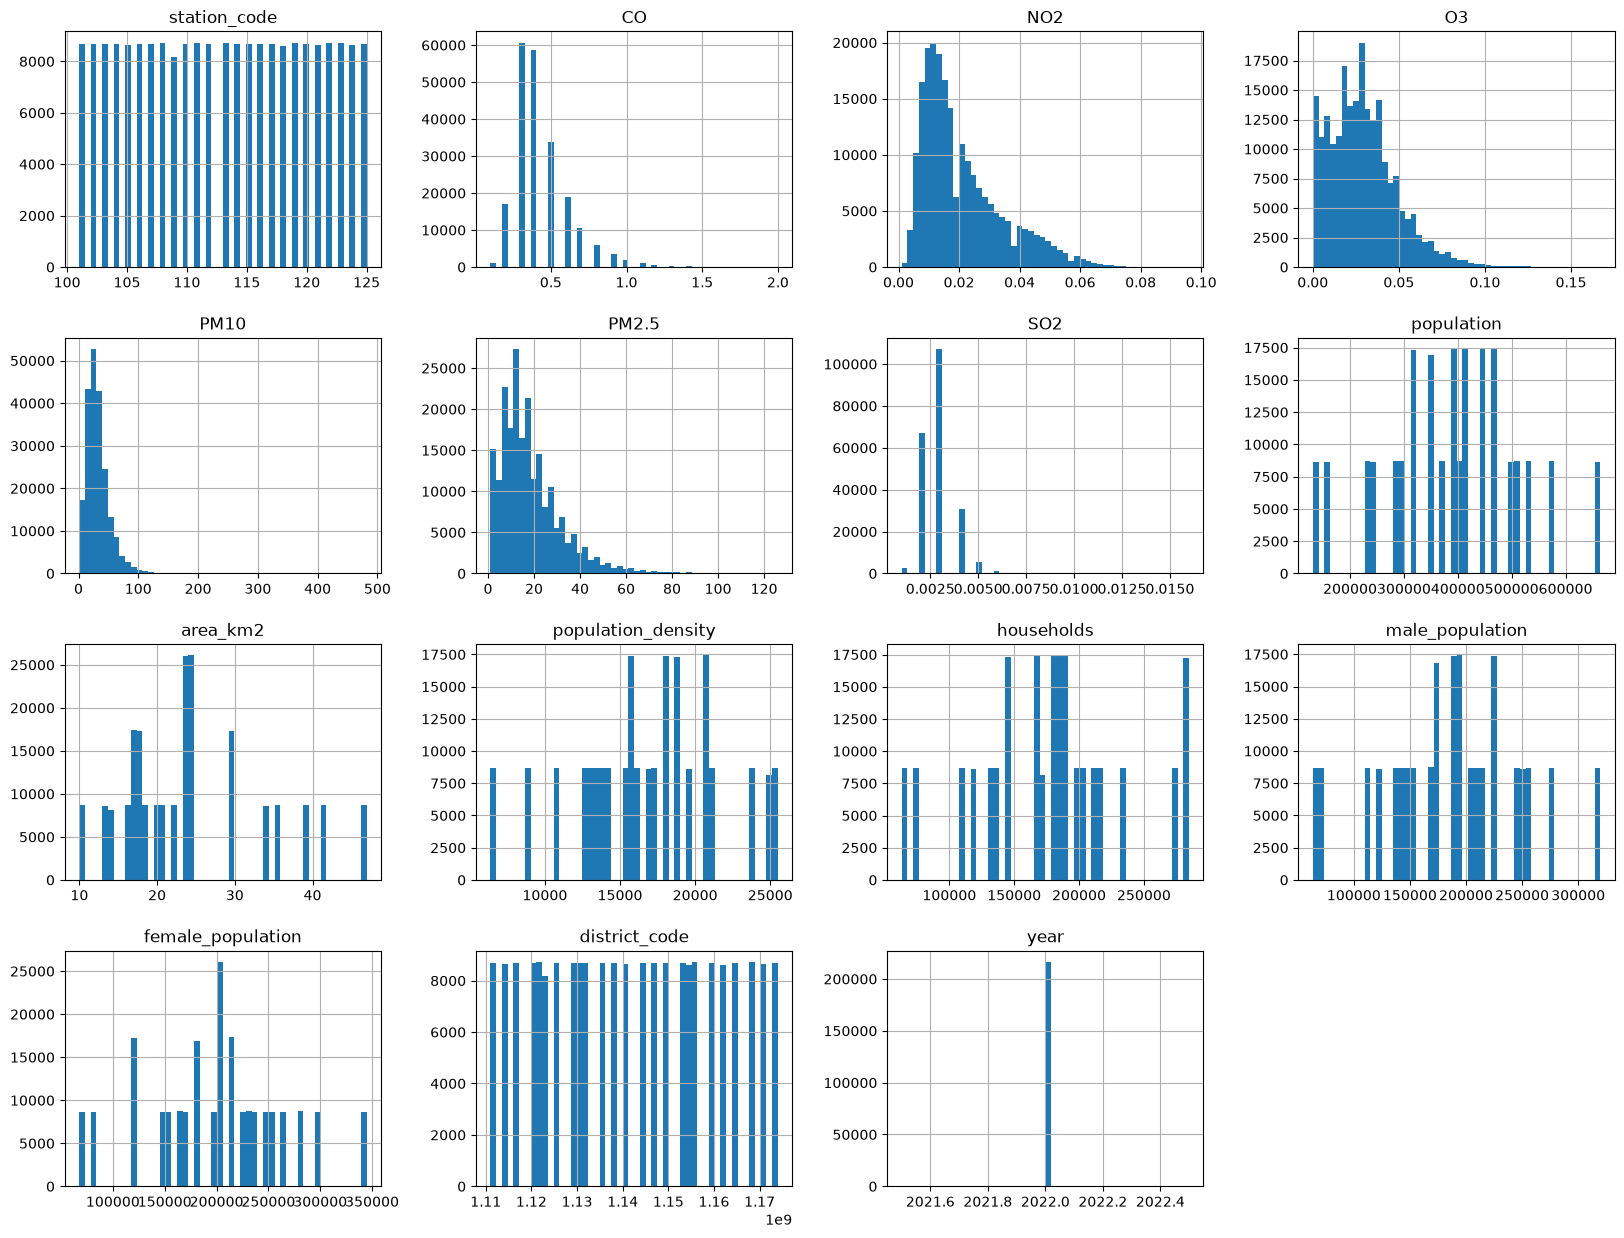

In [3]:
df.hist(bins=50,figsize=(20,15))
plt.show()

Data Profile Table

In [6]:
profile=pd.DataFrame({'Data Type': df_raw.dtypes.astype(str),
                     'Missing Count': df_raw.isnull().sum(),
                     'Missing Percent':df_raw.isnull().sum()/len(df_raw),
                     'Unique Values':df_raw.nunique(),
                     'Minimum':df_raw.min(numeric_only=False),
                     'Maximum':df_raw.max(numeric_only=False)})
display(profile)
                     

,Data Type,Missing Count,Missing Percent,Unique Values,Minimum,Maximum
datetime,str,0,0.000000,8760,1/1/2022 0:00,9/9/2022 9:00
station_code,int64,0,0.000000,25,101,125
district,str,0,0.000000,25,Dobong-gu,Yongsan-gu
CO,float64,1403,0.006479,20,0.1,2.0
NO2,float64,1005,0.004641,93,0.001,0.096
O3,float64,1336,0.006170,154,0.0,0.167
PM10,float64,2409,0.011125,359,1.0,482.0
PM2.5,float64,1740,0.008035,124,1.0,126.0
SO2,float64,1706,0.007878,15,0.001,0.016
population,int64,0,0.000000,25,130785,664514


Data Cleaning and Preprocessing

Data Cleaning 
An analysis of data cleaning revealed that pollutants including CO,NO2,O3,PM10,PM2.5,SO2 contained missing value proportion of approximately 0.648%,0.464%,0.617%,
1.11%,0.803%,0.788% respectively.Although the missingness rate is low,the null values were dispered in almost pollutant columns.Moreover,the dataset recorded the air quality
as a continious time series,removing rows with null values can interrupt temporal continuity and cause a loss in a lot of important information and flawed comparison between
districts.To solve this problem,a group median imputation approach was priority.Unlike Vietnam,air quality in Seoul exhibits cyclical pattern driven by hourly variation and distinct 
seasonal characteristics(Spring,Summer,Autumn,Winter).Furthermore,df.describe() and histogram  indicated that the mean value consistently exceeded the median value,proving a right-skewness distribution 
caused by outliers.The reason of these mistakes may be system error...Therefore,the median was selected over the mean as a central tendency measure to fill missing values group by station_code, hour and season


In [11]:
df['datetime']=pd.to_datetime(df['datetime'])
df['hour']=df['datetime'].dt.hour
df['month']=df['datetime'].dt.month
df['date']=df['datetime'].dt.date
pollutants=['CO','NO2','O3','PM10','PM2.5','SO2']
def get_season(month):
    if month in [12,1,2]:
        return "Winter"
    elif month in [3,4,5]:
        return "Spring"
    elif month in [6,7,8]:
        return "Summer"
    else:
        return "Autumn"
df['season']=df['month'].apply(get_season)
for pollutant in pollutants:
    df[pollutant]=df[pollutant].fillna(df.groupby(['station_code','hour','season'])[pollutant].transform('median'))


After the data imputation process,a unit discrepancy was identified among pollutant metrics.While particular matter(PM10,PM2.5) was recorded in micrograms per cubic meter(ug/m^3),the remaining pollutants were measured in parts per million(ppm).To align with international standardization measurement ,the gaseous pollutants were converted to ug/m^3.Rather than overwriting the original columns,these converted values were added into new columns(NO2_ugm3,SO2_ugm3,O3_ugm3,CO_ugm3).This strategy helps to preserve raw data integrity for baseline verification to prepare machine learning model

In [12]:
#unit normalization
df['NO2_ugm3']=df['NO2']*1880
df['SO2_ugm3']=df['SO2']*2620
df['O3_ugm3']=df['O3']*1960
df['CO_ugm3']=df['CO']*1145
display(df[['NO2','NO2_ugm3','SO2','SO2_ugm3']].head())

,NO2,NO2_ugm3,SO2,SO2_ugm3
0,0.016,30.08,0.003,7.86
1,0.024,45.12,0.003,7.86
2,0.020,37.60,0.003,7.86
3,0.019,35.72,0.004,10.48
4,0.020,37.60,0.003,7.86


Explotary Data Analysis

In [13]:

pollutant_category=df[(df['PM10']>45)|(df['PM2.5']>15)|(df['NO2_ugm3']>25)]
daily_df=df.groupby(['district','date']).agg(PM25=('PM2.5','median'),PM10=('PM10','median'),NO2=('NO2_ugm3','median'),population=('population','first'),po_density=('population_density','first'),area=('area_km2','first')).reset_index()
pollution=daily_df[(daily_df['PM25']>15)|(daily_df['PM10']>45)|(daily_df['NO2']>25)]
district_summary=pollution.groupby(['district']).agg(total_days=('date','count'),district_population=('population','first'),district_popdens=('po_density','first'),dis_area=('area','first')).reset_index()
median_seoul=district_summary['total_days'].quantile(0.75)
serious_pollution=district_summary[district_summary['total_days']>median_seoul]
serious_pollution=serious_pollution.sort_values(by='total_days',ascending=False)
print(f'Median Seoul: {median_seoul} days')
display(serious_pollution)
#Demographic Exposure
dens_seoul=district_summary['district_popdens'].median()
pop_seoul=district_summary['district_population'].median()
filtered_district=district_summary.query('district_population>@pop_seoul|district_popdens>@dens_seoul')
display(filtered_district)
#Area Filter
med_seoularea=district_summary['dis_area'].median()
filtered_area=district_summary.query('dis_area>@med_seoularea')
display(filtered_area)

Median Seoul: 294.0 days


,district,total_days,district_population,district_popdens,dis_area
13,Jung-gu,315,130785,13131,9.96
6,Gangnam-gu,307,534103,13522,39.50
21,Songpa-gu,303,664514,19616,33.88
23,Yeongdeungpo-gu,302,398085,16215,24.55
10,Gwanak-gu,301,501226,16951,29.57
19,Seongbuk-gu,300,441984,17983,24.58


,district,total_days,district_population,district_popdens,dis_area
1,Dongdaemun-gu,251,353601,24873,14.22
2,Dongjak-gu,278,390432,23870,16.36
3,Eunpyeong-gu,255,470602,15838,29.71
5,Gangdong-gu,256,464037,18871,24.59
6,Gangnam-gu,307,534103,13522,39.50
7,Gangseo-gu,282,574638,13862,41.45
8,Geumcheon-gu,292,242818,18649,13.02
9,Guro-gu,240,418418,20794,20.12
10,Gwanak-gu,301,501226,16951,29.57
11,Gwangjin-gu,247,351252,20586,17.06


,district,total_days,district_population,district_popdens,dis_area
3,Eunpyeong-gu,255,470602,15838,29.71
5,Gangdong-gu,256,464037,18871,24.59
6,Gangnam-gu,307,534103,13522,39.50
7,Gangseo-gu,282,574638,13862,41.45
10,Gwanak-gu,301,501226,16951,29.57
12,Jongno-gu,274,152211,6365,23.91
15,Mapo-gu,294,375585,15745,23.85
16,Nowon-gu,261,508014,14335,35.44
17,Seocho-gu,284,408451,8696,46.97
19,Seongbuk-gu,300,441984,17983,24.58


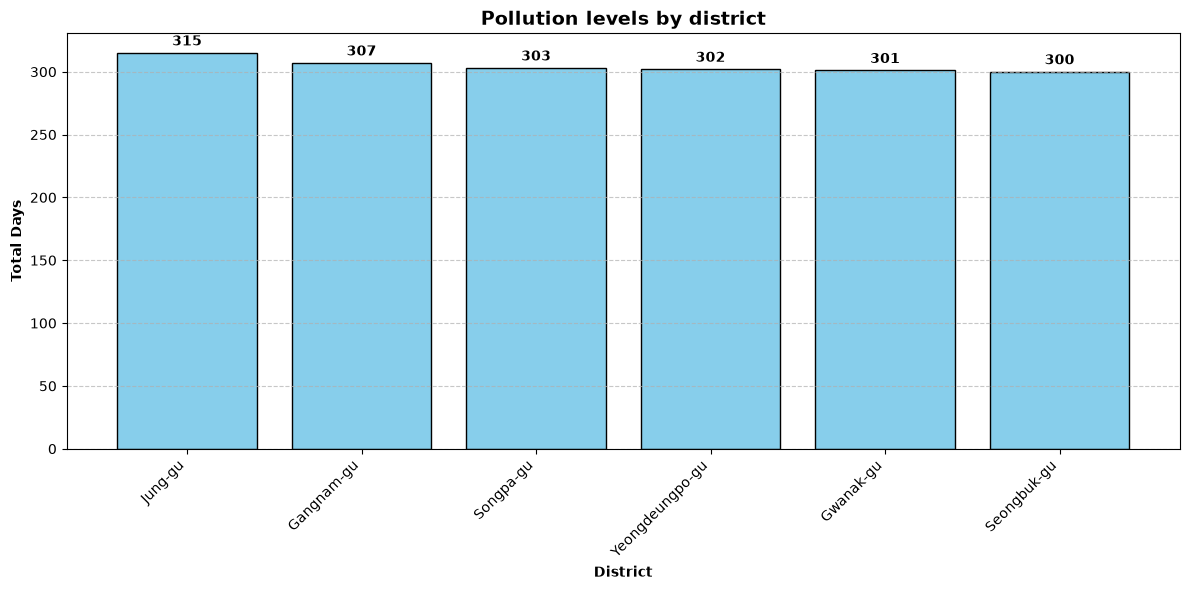

In [15]:
fig,ax=plt.subplots(figsize=(12,6))
bar=ax.bar(serious_pollution['district'],serious_pollution['total_days'],color='skyblue',edgecolor='black')
ax.bar_label(bar,padding=3,fontsize=10,fontweight='bold')
ax.set_title('Pollution levels by district',fontsize=14,fontweight='bold')
ax.set_xlabel('District',fontsize=10,fontweight='bold')
ax.set_ylabel('Total Days',fontsize=10,fontweight='bold')
plt.xticks(rotation=45,ha='right')
plt.grid(axis='y',linestyle='--',alpha=0.7)
plt.tight_layout()
plt.show()

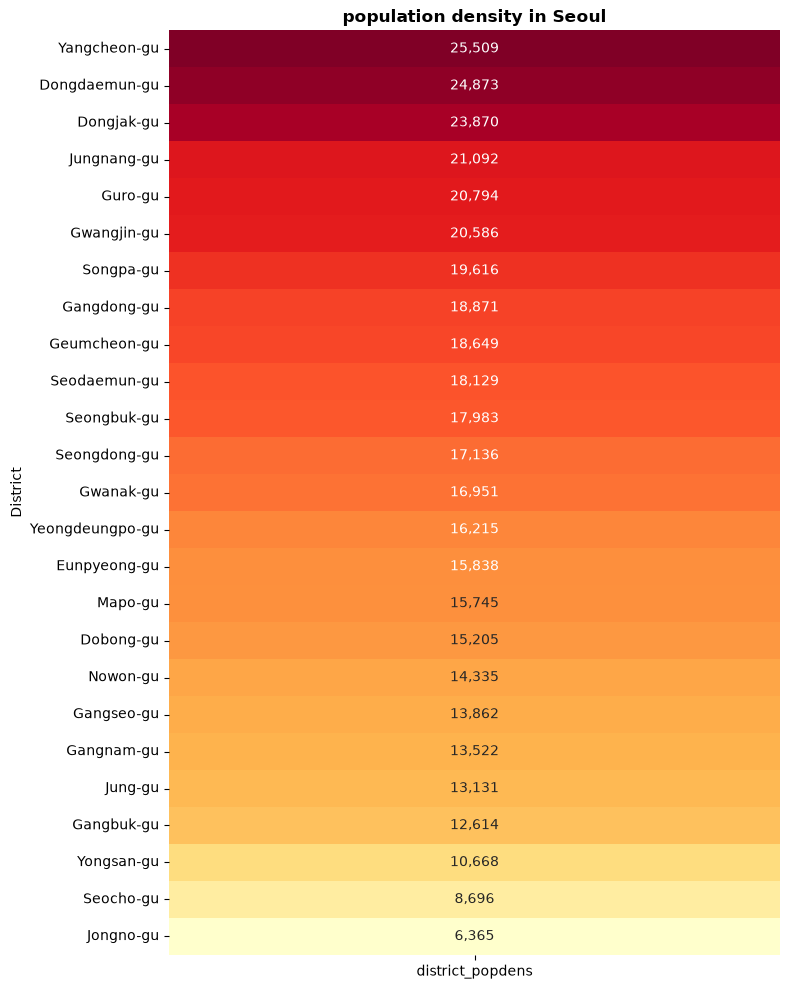

In [8]:
daily_sorted=district_summary.sort_values(by='district_popdens',ascending=False).set_index('district')
plt.figure(figsize=(8,10))
sns.heatmap(daily_sorted[['district_popdens']],annot=True,fmt=',.0f',cmap='YlOrRd',cbar=False)
plt.title('population density in Seoul',fontsize=12,fontweight='bold')
plt.ylabel('District')
plt.tight_layout()
plt.show()

In [10]:
!pip install adjustText
from adjustText import adjust_text

The goal of this project is to visualize the total pollution-exceeding days across the 25 districts  of Seoul in relation to population data,identifying the districts facing severe health risks to strategically determine optimal locations for new air quality monitoring station

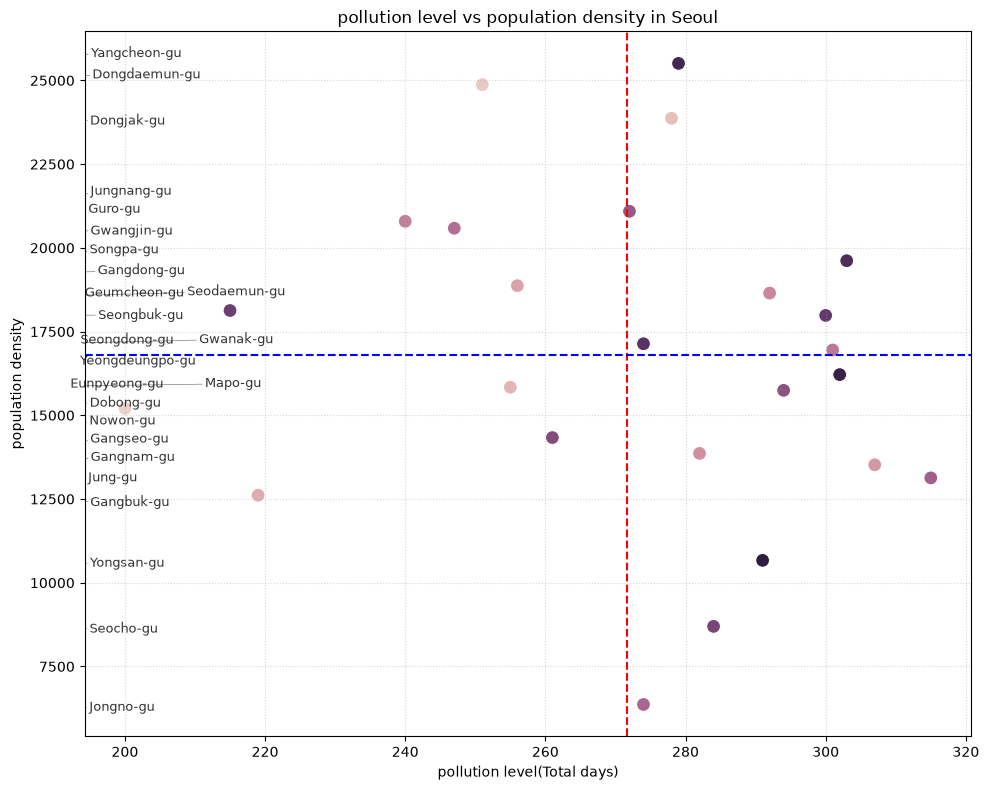

In [11]:
plt.figure(figsize=(10,8))
sns.scatterplot(data=district_summary.reset_index(),x='total_days',y='district_popdens',hue='index',s=100,legend=False)
mean_day=district_summary['total_days'].mean()
mean_pop=district_summary['district_popdens'].mean()
plt.axvline(mean_day,color='red',linestyle='--')
plt.axhline(mean_pop,color='blue',linestyle='--')
texts=[]
for i in range(len(district_summary)):
      t=plt.text(district_summary['total_days'].iloc[i],
            district_summary['district_popdens'].iloc[i],
            district_summary['district'].iloc[i],
            fontsize=9,
            alpha=0.8)
    texts.append(t)
adjust_text(texts,arrowprops=dict(arrowstyle='-',color='gray',lw=0.5))
plt.title('pollution level vs population density in Seoul')
plt.xlabel('pollution level(Total days)')
plt.ylabel('population density')
plt.grid(True,linestyle=':',alpha=0.5)
plt.tight_layout()
plt.show()

In [12]:
median_val=district_summary['total_days'].median()
district_summary['unhealthy']=np.where(district_summary['total_days']>median_val,1,0)
numeric_df=district_summary.select_dtypes(include='number')
corr_matrix=numeric_df.corr()
correlation_with_unhealthy=corr_matrix['unhealthy'].sort_values(ascending=False)
print(correlation_with_unhealthy)

unhealthy              1.000000
total_days             0.779834
dis_area               0.316829
district_population    0.201288
district_popdens      -0.193929
Name: unhealthy, dtype: float64
